In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import linkage, dendrogram

# numpy di Mac kadang memunculkan peringatan matmul palsu (di GMM & Spectral), hasilnya tetap benar
warnings.filterwarnings('ignore', category=RuntimeWarning)

warna = ['#2a78d6', '#eb6834', '#1baf7a']   # warna untuk 3 spesies / 3 kluster

# 1. Unduh dan Import Dataset

In [2]:
url = 'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv'
df = pd.read_csv(url)
print('Shape:', df.shape)
df.head()

Shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


# 2. Eksplorasi dan Pembersihan Data

In [4]:
df.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

In [5]:
fitur = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Hapus baris yang kosong di salah satu fitur atau di species
df_clean = df.dropna(subset=fitur + ['species']).reset_index(drop=True)
print('Jumlah baris sebelum:', len(df))
print('Jumlah baris sesudah:', len(df_clean))
df_clean['species'].value_counts()

Jumlah baris sebelum: 344
Jumlah baris sesudah: 342


species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

In [6]:
df_clean[fitur].describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


Skala beda jauh: `body_mass_g` ribuan (gram), kolom lain puluhan–ratusan (mm) → perlu standardisasi.

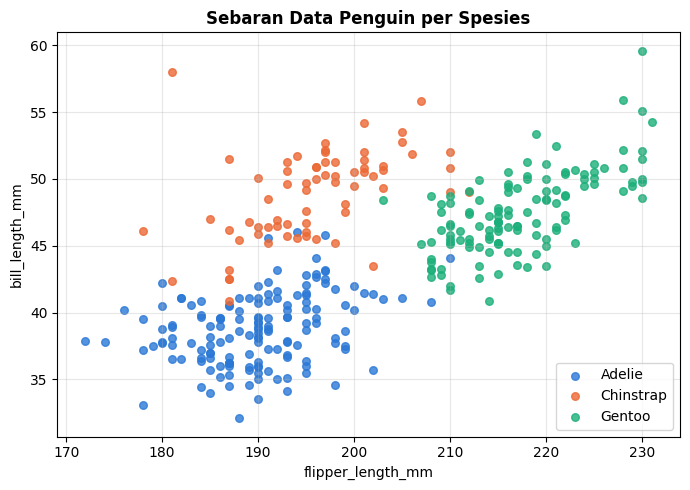

In [7]:
# Sebaran data sebelum clustering (warna = spesies asli)
fig, ax = plt.subplots(figsize=(7, 5))
for w, (spesies, data) in zip(warna, df_clean.groupby('species')):
    ax.scatter(data['flipper_length_mm'], data['bill_length_mm'], color=w, s=30, alpha=0.8, label=spesies)
ax.set_xlabel('flipper_length_mm')
ax.set_ylabel('bill_length_mm')
ax.set_title('Sebaran Data Penguin per Spesies', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Standardisasi Data

In [8]:
X = df_clean[fitur]
y = df_clean['species']   # hanya untuk evaluasi, tidak ikut clustering

X_scaled = StandardScaler().fit_transform(X)
pd.DataFrame(X_scaled, columns=fitur).describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00
min,-2.17,-2.05,-2.06,-1.88
25%,-0.86,-0.79,-0.78,-0.81
50%,0.10,0.08,-0.28,-0.19
75%,0.84,0.79,0.86,0.68
max,2.88,2.21,2.14,2.62


# 4. Penerapan Algoritma

## Agglomerative Clustering (linkage: ward)

In [9]:
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
label_agg = agg.fit_predict(X_scaled)
pd.Series(label_agg).value_counts().sort_index()

0    162
1    123
2     57
Name: count, dtype: int64

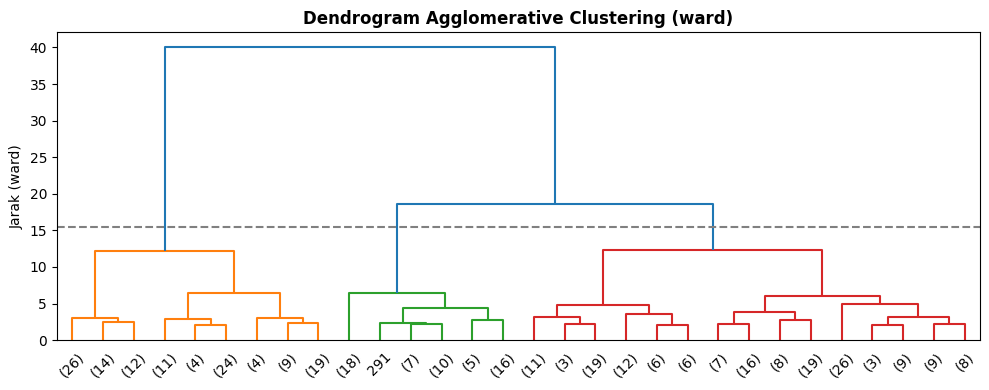

In [10]:
# Dendrogram (ditampilkan 30 gabungan terakhir supaya terbaca)
Z = linkage(X_scaled, method='ward')
garis = (Z[-3, 2] + Z[-2, 2]) / 2   # garis potong di antara 2 gabungan terakhir -> 3 kluster

fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(Z, truncate_mode='lastp', p=30, color_threshold=garis, ax=ax)
ax.axhline(garis, color='gray', linestyle='--')
ax.set_ylabel('Jarak (ward)')
ax.set_title('Dendrogram Agglomerative Clustering (ward)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## DBSCAN

In [11]:
def jumlah_kluster(label):
    return len(set(label) - {-1})   # -1 = noise, bukan kluster

# Titik awal: eps 0.5, MinPts 5
label_db05 = DBSCAN(eps=0.5, min_samples=5).fit_predict(X_scaled)
print('Jumlah kluster:', jumlah_kluster(label_db05))
print('Jumlah noise:', (label_db05 == -1).sum())

Jumlah kluster: 4
Jumlah noise: 69


In [12]:
# Coba beberapa nilai eps
hasil_eps = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    label = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    hasil_eps.append({'eps': eps, 'jumlah_kluster': jumlah_kluster(label), 'jumlah_noise': (label == -1).sum()})
pd.DataFrame(hasil_eps)

,eps,jumlah_kluster,jumlah_noise
0,0.3,4,317
1,0.4,10,171
2,0.5,4,69
3,0.6,2,33
4,0.7,2,16
5,0.8,2,5
6,0.9,2,2
7,1.0,2,1


eps 0.5 → 4 kluster tapi 69 noise (20% data). eps 0.6–1.0 → stabil 2 kluster. Dipakai **eps 0.8** (noise tinggal 5).

In [13]:
label_db = DBSCAN(eps=0.8, min_samples=5).fit_predict(X_scaled)
print('Jumlah kluster:', jumlah_kluster(label_db))
print('Jumlah noise:', (label_db == -1).sum())

Jumlah kluster: 2
Jumlah noise: 5


## Gaussian Mixture Models (GMM)

In [14]:
# n_init=10: dicoba 10 titik awal, diambil yang terbaik
gmm = GaussianMixture(n_components=3, n_init=10, random_state=42)
label_gmm = gmm.fit_predict(X_scaled)
pd.Series(label_gmm).value_counts().sort_index()

0    123
1    152
2     67
Name: count, dtype: int64

## Spectral Clustering

In [15]:
spectral = SpectralClustering(n_clusters=3, random_state=42)
label_spec = spectral.fit_predict(X_scaled)
pd.Series(label_spec).value_counts().sort_index()

0    176
1    123
2     43
Name: count, dtype: int64

## Scatter Plot Hasil Clustering

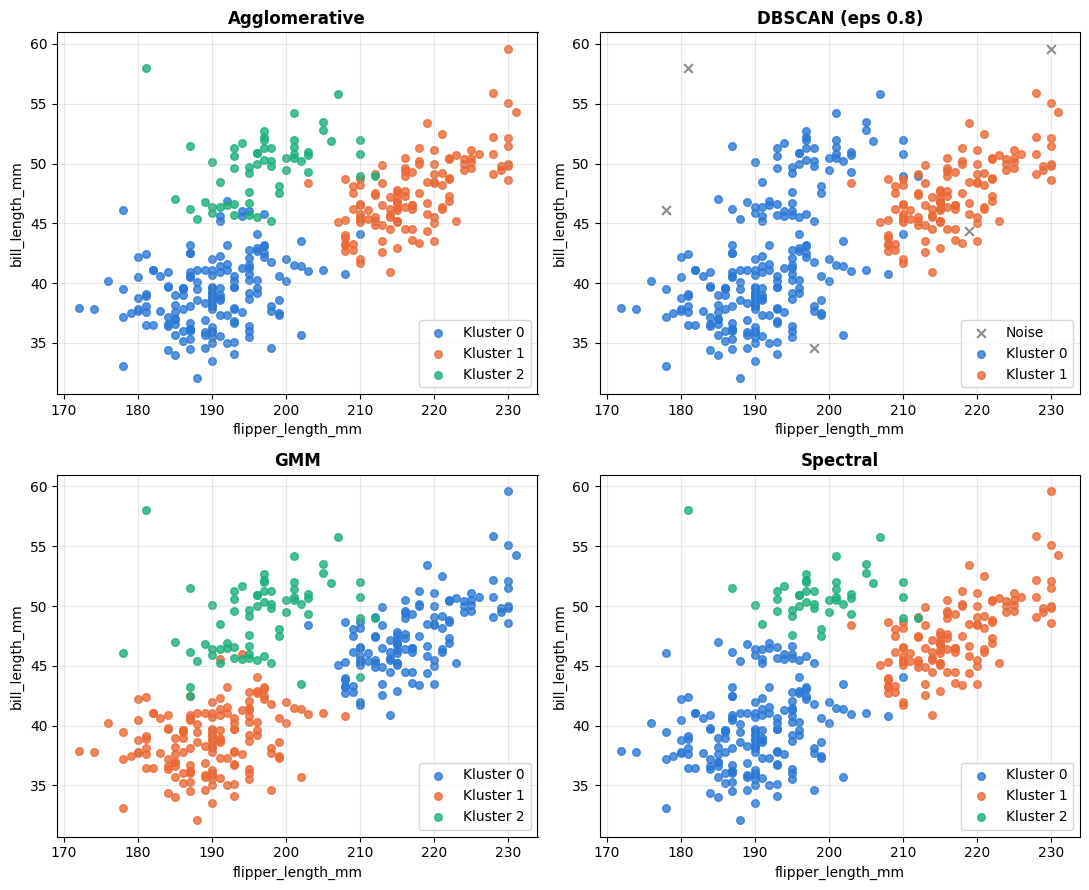

In [16]:
hasil = {'Agglomerative': label_agg, 'DBSCAN (eps 0.8)': label_db, 'GMM': label_gmm, 'Spectral': label_spec}

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (nama, label) in zip(axes.flat, hasil.items()):
    for k in sorted(set(label)):
        data = df_clean[label == k]
        if k == -1:
            ax.scatter(data['flipper_length_mm'], data['bill_length_mm'], color='#8c8c8c', marker='x', s=40, label='Noise')
        else:
            ax.scatter(data['flipper_length_mm'], data['bill_length_mm'], color=warna[k], s=30, alpha=0.8, label=f'Kluster {k}')
    ax.set_title(nama, fontsize=12, fontweight='bold')
    ax.set_xlabel('flipper_length_mm')
    ax.set_ylabel('bill_length_mm')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Evaluasi Hasil Clustering

In [17]:
# Silhouette Score (DBSCAN: titik noise tidak ikut dihitung)
silhouette = {}
for nama, label in hasil.items():
    bukan_noise = label != -1
    silhouette[nama] = silhouette_score(X_scaled[bukan_noise], label[bukan_noise])

print('Titik noise DBSCAN yang dibuang:', (label_db == -1).sum())
pd.Series(silhouette, name='Silhouette').round(3)

Titik noise DBSCAN yang dibuang: 5


Agglomerative       0.454
DBSCAN (eps 0.8)    0.536
GMM                 0.455
Spectral            0.462
Name: Silhouette, dtype: float64

In [18]:
# Rand Index dan NMI terhadap species
eksternal = pd.DataFrame({nama: {'Rand Index': rand_score(y, label),
                                'NMI': normalized_mutual_info_score(y, label)} for nama, label in hasil.items()}).T
eksternal.round(3)

,Rand Index,NMI
Agglomerative,0.961,0.901
DBSCAN (eps 0.8),0.821,0.730
GMM,0.982,0.935
Spectral,0.917,0.831


In [19]:
# Tabel silang spesies vs kluster: spesies mana yang tercampur
for nama, label in hasil.items():
    print(nama)
    print(pd.crosstab(y, label, colnames=['kluster']), '\n')

Agglomerative
kluster      0    1   2
species                
Adelie     151    0   0
Chinstrap   11    0  57
Gentoo       0  123   0 

DBSCAN (eps 0.8)
kluster    -1    0    1
species                
Adelie      1  150    0
Chinstrap   2   66    0
Gentoo      2    0  121 

GMM
kluster      0    1   2
species                
Adelie       0  149   2
Chinstrap    0    3  65
Gentoo     123    0   0 

Spectral
kluster      0    1   2
species                
Adelie     151    0   0
Chinstrap   25    0  43
Gentoo       0  123   0 



In [20]:
# Uji kestabilan: jalankan ulang di 90% data acak (3 kali),
# lalu bandingkan dengan hasil data penuh pada titik yang sama (Rand Index, 1 = sama persis)
model = {'Agglomerative': AgglomerativeClustering(n_clusters=3, linkage='ward'),
         'DBSCAN (eps 0.8)': DBSCAN(eps=0.8, min_samples=5),
         'GMM': GaussianMixture(n_components=3, n_init=10, random_state=42),
         'Spectral': SpectralClustering(n_clusters=3, random_state=42)}

rng = np.random.default_rng(42)
stabil = {nama: [] for nama in model}
for i in range(3):
    idx = rng.choice(len(X_scaled), size=int(0.9 * len(X_scaled)), replace=False)
    for nama, m in model.items():
        label_90 = m.fit_predict(X_scaled[idx])
        stabil[nama].append(rand_score(hasil[nama][idx], label_90))

pd.DataFrame(stabil, index=['Percobaan 1', 'Percobaan 2', 'Percobaan 3']).T.round(3)

,Percobaan 1,Percobaan 2,Percobaan 3
Agglomerative,0.968,0.972,0.971
DBSCAN (eps 0.8),0.996,0.998,0.998
GMM,0.996,1.000,1.000
Spectral,1.000,1.000,1.000


In [21]:
# Tabel perbandingan semua algoritma
ringkasan = pd.DataFrame({
    'Jumlah kluster': {nama: jumlah_kluster(label) for nama, label in hasil.items()},
    'Noise': {nama: (label == -1).sum() for nama, label in hasil.items()},
    'Silhouette': silhouette,
    'Rand Index': eksternal['Rand Index'],
    'NMI': eksternal['NMI'],
    'Stabilitas (rata-rata)': {nama: np.mean(nilai) for nama, nilai in stabil.items()},
})
ringkasan.round(3)

,Jumlah kluster,Noise,Silhouette,Rand Index,NMI,Stabilitas (rata-rata)
Agglomerative,3,0,0.454,0.961,0.901,0.970
DBSCAN (eps 0.8),2,5,0.536,0.821,0.730,0.997
GMM,3,0,0.455,0.982,0.935,0.999
Spectral,3,0,0.462,0.917,0.831,1.000


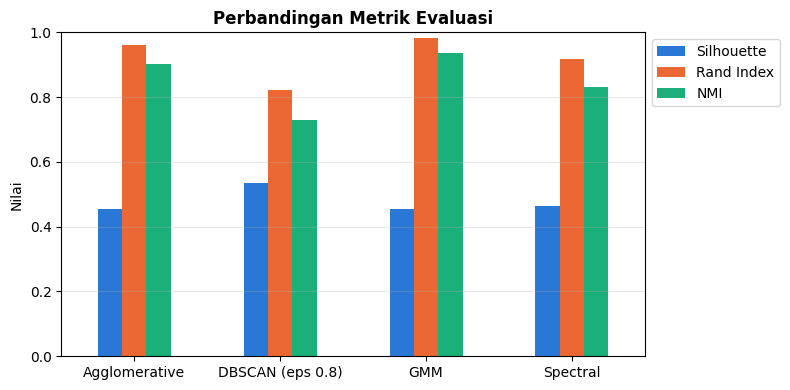

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
ringkasan[['Silhouette', 'Rand Index', 'NMI']].plot(kind='bar', color=warna, ax=ax, rot=0)
ax.set_ylim(0, 1)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax.set_ylabel('Nilai')
ax.set_title('Perbandingan Metrik Evaluasi', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Analisis**
- **GMM** paling mirip spesies: Rand Index 0.982, NMI 0.935, hanya 5 penguin salah kelompok.
- **Agglomerative**: 11 Chinstrap masuk kelompok Adelie. **Spectral**: 25 Chinstrap masuk kelompok Adelie.
- **DBSCAN** hanya menemukan 2 kluster (Adelie + Chinstrap jadi satu). Silhouette-nya tertinggi karena 2 kluster itu terpisah jauh, bukan karena lebih sesuai.
- Semua algoritma stabil (≥ 0.97) saat dijalankan ulang di 90% data.

# 6. Kesimpulan

**GMM paling cocok** untuk dataset ini: Rand Index dan NMI tertinggi, stabil (0.999), dan bisa menangkap kluster yang lonjong dengan ukuran berbeda-beda.